# Online Gaming Behaviour Using Machine Learning

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Importing Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

In [3]:
df = pd.read_csv("online_gaming_behavior_dataset.csv")

In [4]:
df.shape

(40034, 13)

In [5]:
df.head()

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


In [6]:
df.tail()

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
40029,49029,32,Male,USA,Strategy,20.619662,0,Easy,4,75,85,14,Medium
40030,49030,44,Female,Other,Simulation,13.539280,0,Hard,19,114,71,27,High
40031,49031,15,Female,USA,RPG,0.240057,1,Easy,10,176,29,1,High
40032,49032,34,Male,USA,Sports,14.017818,1,Medium,3,128,70,10,Medium
40033,49033,19,Male,USA,Sports,10.083804,0,Easy,13,84,72,39,Medium


In [7]:
df.columns

Index(['PlayerID', 'Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours',
       'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek',
       'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked',
       'EngagementLevel'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  object 
 3   Location                   40034 non-null  object 
 4   GameGenre                  40034 non-null  object 
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  object 
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  object 
dtypes: float64(1), int64(7), object(5)
memory usag

In [9]:
df.describe()

,PlayerID,Age,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
count,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000
mean,29016.500000,31.992531,12.024365,0.200854,9.471774,94.792252,49.655568,24.526477
std,11556.964675,10.043227,6.914638,0.400644,5.763667,49.011375,28.588379,14.430726
min,9000.000000,15.000000,0.000115,0.000000,0.000000,10.000000,1.000000,0.000000
25%,19008.250000,23.000000,6.067501,0.000000,4.000000,52.000000,25.000000,12.000000
50%,29016.500000,32.000000,12.008002,0.000000,9.000000,95.000000,49.000000,25.000000
75%,39024.750000,41.000000,17.963831,0.000000,14.000000,137.000000,74.000000,37.000000
max,49033.000000,49.000000,23.999592,1.000000,19.000000,179.000000,99.000000,49.000000


In [10]:
df.isnull().sum()

PlayerID                     0
Age                          0
Gender                       0
Location                     0
GameGenre                    0
PlayTimeHours                0
InGamePurchases              0
GameDifficulty               0
SessionsPerWeek              0
AvgSessionDurationMinutes    0
PlayerLevel                  0
AchievementsUnlocked         0
EngagementLevel              0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df = df.drop_duplicates()

In [13]:
df.head(10)

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium
5,9005,37,Male,Europe,RPG,20.561855,0,Easy,2,81,74,22,Low
6,9006,25,Male,USA,Action,9.752716,0,Hard,1,50,13,2,Low
7,9007,25,Female,Asia,RPG,4.401729,0,Medium,10,48,27,23,Medium
8,9008,38,Female,Europe,Simulation,18.152733,0,Easy,5,101,23,41,Medium
9,9009,38,Female,Other,Sports,23.942772,0,Easy,13,95,99,36,High


In [14]:
X = df.drop("EngagementLevel", axis=1)

In [15]:
y = df["EngagementLevel"]

In [16]:
X = pd.get_dummies(X, drop_first=True)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [20]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [21]:
import os

print(os.getcwd())

C:\Users\ritik


# Machine Learning Algorithms

# Logistic Regression

In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
lr = LogisticRegression()

In [24]:
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [25]:
y_pred_lr = lr.predict(X_test)
y_pred_lr

array(['Medium', 'Medium', 'Medium', ..., 'Medium', 'Medium', 'Medium'],
      shape=(8007,), dtype=object)

In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [27]:
acc = accuracy_score(y_test, y_pred_lr)
print("Accuracy:", acc)

Accuracy: 0.8212813787935557


In [28]:
print("Precision :",precision_score(y_test,y_pred_lr,average='weighted'))

Precision : 0.8233494653770085


In [29]:
print("Recall :",recall_score(y_test,y_pred_lr,average='weighted'))

Recall : 0.8212813787935557


In [30]:
print("F1 Score :",f1_score(y_test,y_pred_lr,average='weighted'))

F1 Score : 0.8198789997553453


In [31]:
cm = confusion_matrix(y_test, y_pred_lr)
print(cm)

[[1672   58  305]
 [  61 1466  566]
 [ 146  295 3438]]


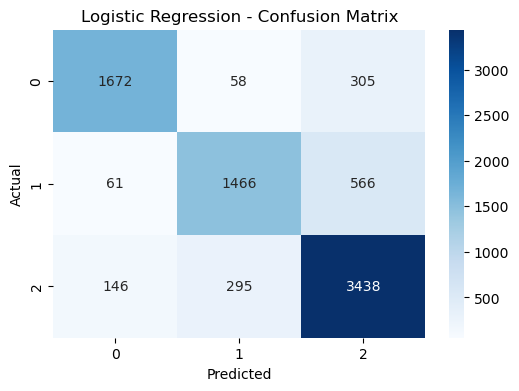

In [32]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Observation 

Logistic Regression successfully classified the player engagement levels with good overall performance. 
It produced reliable predictions and served as an effective baseline model. However, more advanced algorithms may achieve higher accuracy on complex datasets.

# Decision Tree

In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

In [34]:
dt = DecisionTreeClassifier(random_state=42)

In [35]:
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [36]:
y_pred_dt = dt.predict(X_test)
y_pred_dt

array(['Low', 'Medium', 'Low', ..., 'Medium', 'Medium', 'Medium'],
      shape=(8007,), dtype=object)

In [37]:
acc = accuracy_score(y_test, y_pred_dt)
print("Accuracy:", acc)

Accuracy: 0.8292743849132009


In [38]:
print("Precision :", precision_score(y_test, y_pred_dt, average='weighted'))

Precision : 0.8298850717749399


In [39]:
print("Recall :", recall_score(y_test, y_pred_dt, average='weighted'))

Recall : 0.8292743849132009


In [40]:
print("F1 Score :", f1_score(y_test, y_pred_dt, average='weighted'))


F1 Score : 0.8295112318725663


In [41]:
cm = confusion_matrix(y_test, y_pred_dt)
print(cm)

[[1668  128  239]
 [ 143 1677  273]
 [ 266  318 3295]]


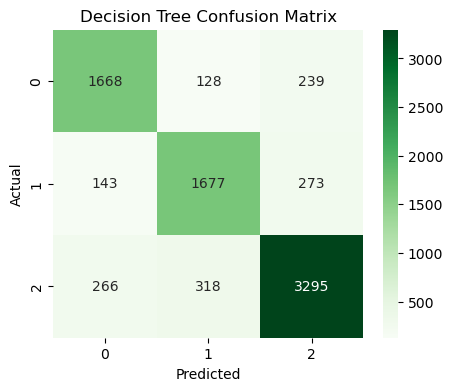

In [42]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [43]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

        High       0.80      0.82      0.81      2035
         Low       0.79      0.80      0.80      2093
      Medium       0.87      0.85      0.86      3879

    accuracy                           0.83      8007
   macro avg       0.82      0.82      0.82      8007
weighted avg       0.83      0.83      0.83      8007



### Observation

The model's performance was evaluated using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix. 
Decision Trees can capture complex relationships but may overfit if not properly controlled.

<br><br><br><br>

# Random Forest Classifier

In [44]:
from sklearn.ensemble import RandomForestClassifier

In [45]:
rf = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    n_jobs=-1
)

In [46]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [47]:
y_pred_rf = rf.predict(X_test)
y_pred_rf

array(['Medium', 'Medium', 'Low', ..., 'Medium', 'Medium', 'Medium'],
      shape=(8007,), dtype=object)

In [48]:
acc = accuracy_score(y_test, y_pred_rf)
print("Accuracy:", acc)

Accuracy: 0.8729861371300113


In [49]:
print("Precision :", precision_score(y_test, y_pred_rf, average='weighted'))

Precision : 0.8769582012954993


In [50]:
print("Recall :", recall_score(y_test, y_pred_rf, average='weighted'))

Recall : 0.8729861371300113


In [51]:
print("F1 Score :", f1_score(y_test, y_pred_rf, average='weighted'))

F1 Score : 0.8718961152286284


In [52]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

[[1632   64  339]
 [  55 1691  347]
 [ 118   94 3667]]


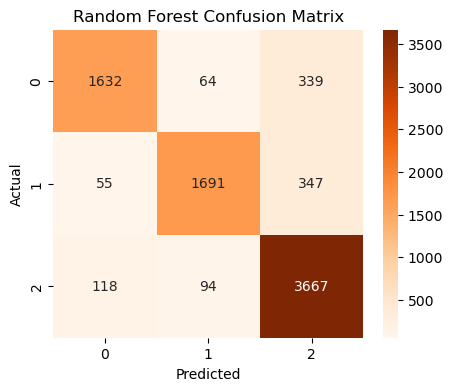

In [53]:
plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Oranges")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [54]:
print(classification_report(y_test, y_pred_rf, zero_division=0))

              precision    recall  f1-score   support

        High       0.90      0.80      0.85      2035
         Low       0.91      0.81      0.86      2093
      Medium       0.84      0.95      0.89      3879

    accuracy                           0.87      8007
   macro avg       0.89      0.85      0.87      8007
weighted avg       0.88      0.87      0.87      8007



## Observation

Random Forest achieved high accuracy but failed to detect any fraudulent transactions, resulting in zero Recall and F1-Score.

<br><br><br><br>

# KNN Model

In [55]:
from sklearn.decomposition import PCA

In [56]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [57]:
from sklearn.neighbors import KNeighborsClassifier

In [58]:
for k in [3, 5, 7, 9]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca, y_train)

    prediction = knn.predict(X_test_pca)
    accuracy = accuracy_score(y_test, prediction)
    print(f"K = {k}, Accuracy = {accuracy:.4f}")

K = 3, Accuracy = 0.6648
K = 5, Accuracy = 0.6803
K = 7, Accuracy = 0.6979
K = 9, Accuracy = 0.7089


In [59]:
best_knn = KNeighborsClassifier(n_neighbors=9)
best_knn.fit(X_train_pca, y_train)
y_pred_knn = best_knn.predict(X_test_pca)

In [60]:
acc = accuracy_score(y_test, y_pred_knn)
print("Accuracy:", acc)

Accuracy: 0.7088797302360434


In [61]:
print("Precision :", precision_score(y_test, y_pred_knn, average='weighted'))

Precision : 0.7166253986835806


In [62]:
print("Recall :", recall_score(y_test, y_pred_knn, average='weighted'))

Recall : 0.7088797302360434


In [63]:
print("F1 Score :", f1_score(y_test, y_pred_knn, average='weighted'))

F1 Score : 0.7029543530783314


In [64]:
cm_knn = confusion_matrix(y_test, y_pred_knn)
print(cm_knn)

[[1408   47  580]
 [  72 1065  956]
 [ 352  324 3203]]


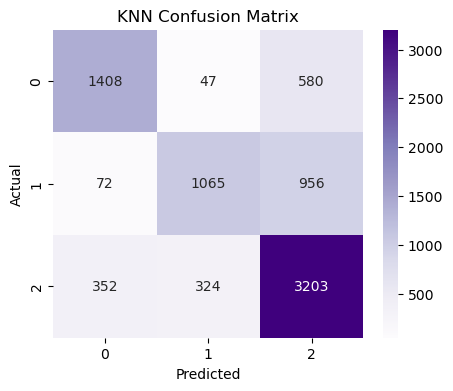

In [65]:
plt.figure(figsize=(5,4))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Purples")
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [66]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

        High       0.77      0.69      0.73      2035
         Low       0.74      0.51      0.60      2093
      Medium       0.68      0.83      0.74      3879

    accuracy                           0.71      8007
   macro avg       0.73      0.68      0.69      8007
weighted avg       0.72      0.71      0.70      8007



## Observation
KNN performed best with K = 9. It achieved high accuracy but detected very few fraud cases, giving a very low Recall and F1-Score.

<br><br><br><br>

# SVM

In [67]:
from sklearn.svm import SVC

svm = SVC()

In [68]:
svm.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [69]:
y_pred_svm = svm.predict(X_test)
y_pred_svm

array(['Medium', 'Medium', 'Low', ..., 'Medium', 'Medium', 'Medium'],
      shape=(8007,), dtype=object)

In [70]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_svm, average='weighted'))
print("F1:", f1_score(y_test, y_pred_svm, average='weighted'))

Accuracy: 0.8821031597352317
Precision: 0.8830649196662494
Recall: 0.8821031597352317
F1: 0.8815654609833158


In [71]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
print(cm_svm)

[[1724   65  246]
 [  59 1734  300]
 [ 118  156 3605]]


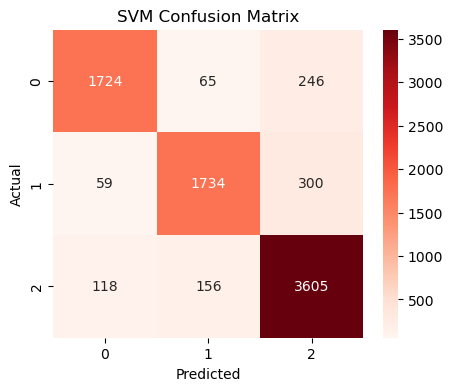

In [72]:
plt.figure(figsize=(5,4))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Reds")
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Comparison Table
The performance of all four machine learning models was compared using Accuracy, Precision, Recall and F1-Score.

In [73]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm),
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.821281
1,Decision Tree,0.829274
2,Random Forest,0.872986
3,KNN,0.708880
4,SVM,0.882103


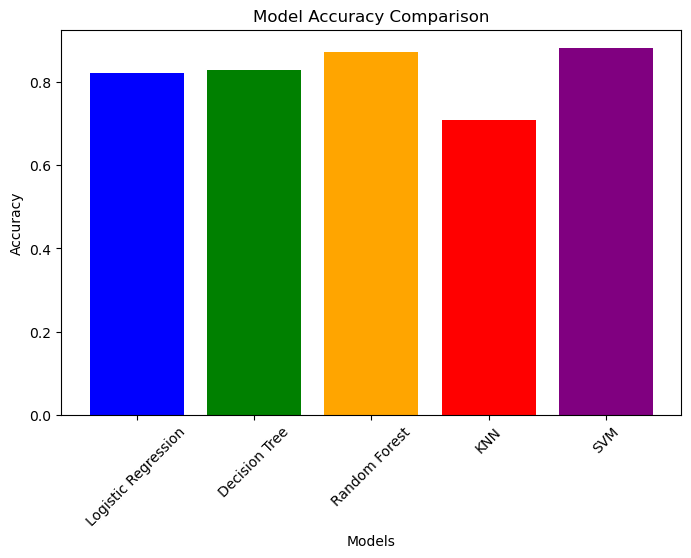

In [74]:
plt.figure(figsize=(8,5))

colors = ['blue', 'green', 'orange', 'red', 'purple']

plt.bar(results["Model"], results["Accuracy"], color=colors)

plt.xticks(rotation=45)
plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.show()

In [1]:
# ---------- Setup for the improved section (self-contained: runs even if the old cells were not run) ----------
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.base import clone
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
ORDER = ["Low", "Medium", "High"]          # natural order of engagement
sns.set_theme(style="whitegrid")

# Fresh copy of the data -> the original `df` and its variables stay untouched
data = pd.read_csv("online_gaming_behavior_dataset.csv").drop_duplicates().reset_index(drop=True)
data["EngagementLevel"] = pd.Categorical(data["EngagementLevel"], categories=ORDER, ordered=True)

NUMERIC_COLS = ["Age", "PlayTimeHours", "SessionsPerWeek",
                "AvgSessionDurationMinutes", "PlayerLevel", "AchievementsUnlocked"]
CATEGORICAL_COLS = ["Gender", "Location", "GameGenre", "GameDifficulty", "InGamePurchases"]

print("Shape:", data.shape)
print("Missing values:", int(data.isnull().sum().sum()))

Shape: (40034, 13)
Missing values: 0


In [2]:
data_dictionary = pd.DataFrame({
    "Column": ["PlayerID", "Age", "Gender", "Location", "GameGenre", "PlayTimeHours",
               "InGamePurchases", "GameDifficulty", "SessionsPerWeek",
               "AvgSessionDurationMinutes", "PlayerLevel", "AchievementsUnlocked", "EngagementLevel"],
    "Meaning": ["Unique player identifier (not used as a feature)",
                "Player age in years",
                "Player gender",
                "Player region",
                "Genre of the game played",
                "Total hours played",
                "Whether the player makes in-game purchases (0 = no, 1 = yes)",
                "Difficulty level chosen in the game",
                "Number of play sessions per week",
                "Average length of one session, in minutes",
                "Current level reached in the game",
                "Number of achievements unlocked",
                "TARGET: engagement category (Low / Medium / High)"],
    "Type": ["Identifier", "Numeric", "Categorical", "Categorical", "Categorical", "Numeric",
             "Binary", "Categorical", "Numeric", "Numeric", "Numeric", "Numeric", "Target"]
})
data_dictionary

,Column,Meaning,Type
0,PlayerID,Unique player identifier (not used as a feature),Identifier
1,Age,Player age in years,Numeric
2,Gender,Player gender,Categorical
3,Location,Player region,Categorical
4,GameGenre,Genre of the game played,Categorical
5,PlayTimeHours,Total hours played,Numeric
6,InGamePurchases,Whether the player makes in-game purchases (0 ...,Binary
7,GameDifficulty,Difficulty level chosen in the game,Categorical
8,SessionsPerWeek,Number of play sessions per week,Numeric
9,AvgSessionDurationMinutes,"Average length of one session, in minutes",Numeric


EngagementLevel
Low       25.8 %
Medium    48.4 %
High      25.8 %
Name: count, dtype: object


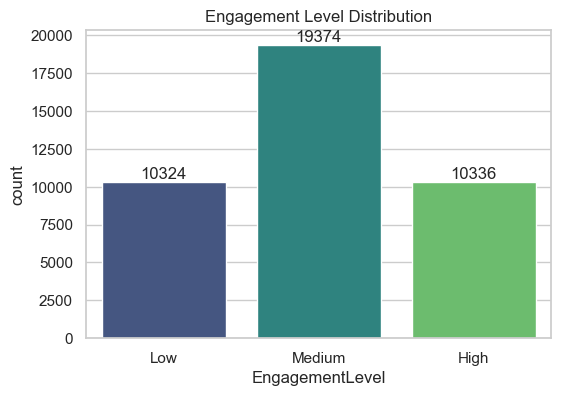

In [3]:
# 3.1 Target distribution
counts = data["EngagementLevel"].value_counts().reindex(ORDER)
print((counts / counts.sum() * 100).round(1).astype(str) + " %")

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=data, x="EngagementLevel", order=ORDER, palette="viridis")
for c in ax.containers:
    ax.bar_label(c)
plt.title("Engagement Level Distribution")
plt.show()

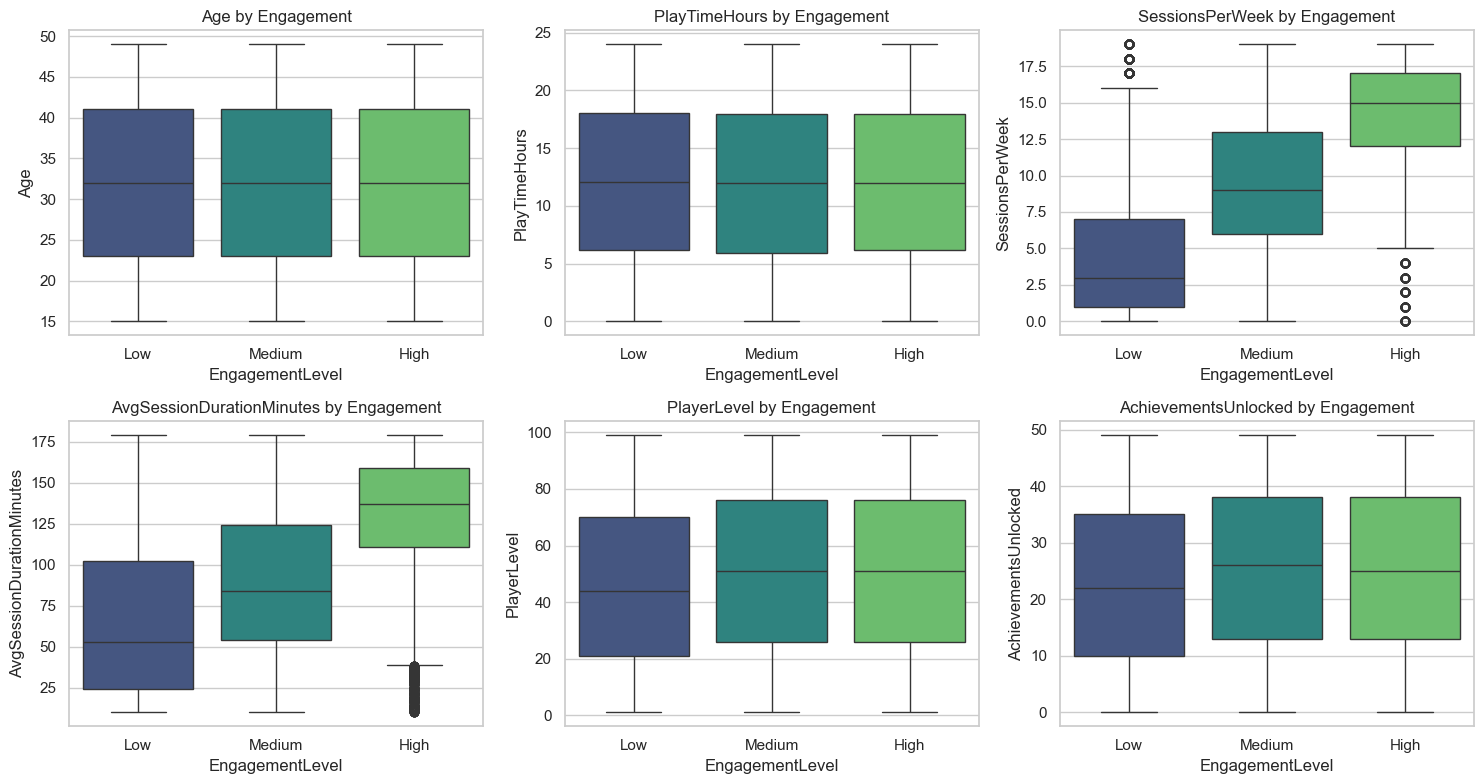

,Age,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,InGamePurchases
EngagementLevel,,,,,,,
Low,31.90,12.10,4.53,66.88,46.10,22.66,0.20
Medium,32.08,11.96,9.55,89.86,50.93,25.22,0.20
High,31.92,12.07,14.25,131.92,50.82,25.10,0.21


In [4]:
# 3.2 Numeric behaviours vs engagement (box plots)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    sns.boxplot(data=data, x="EngagementLevel", y=col, order=ORDER, palette="viridis", ax=ax)
    ax.set_title(f"{col} by Engagement")
plt.tight_layout()
plt.show()

# Average of each behaviour per engagement group
data.groupby("EngagementLevel", observed=True)[NUMERIC_COLS + ["InGamePurchases"]].mean().round(2)

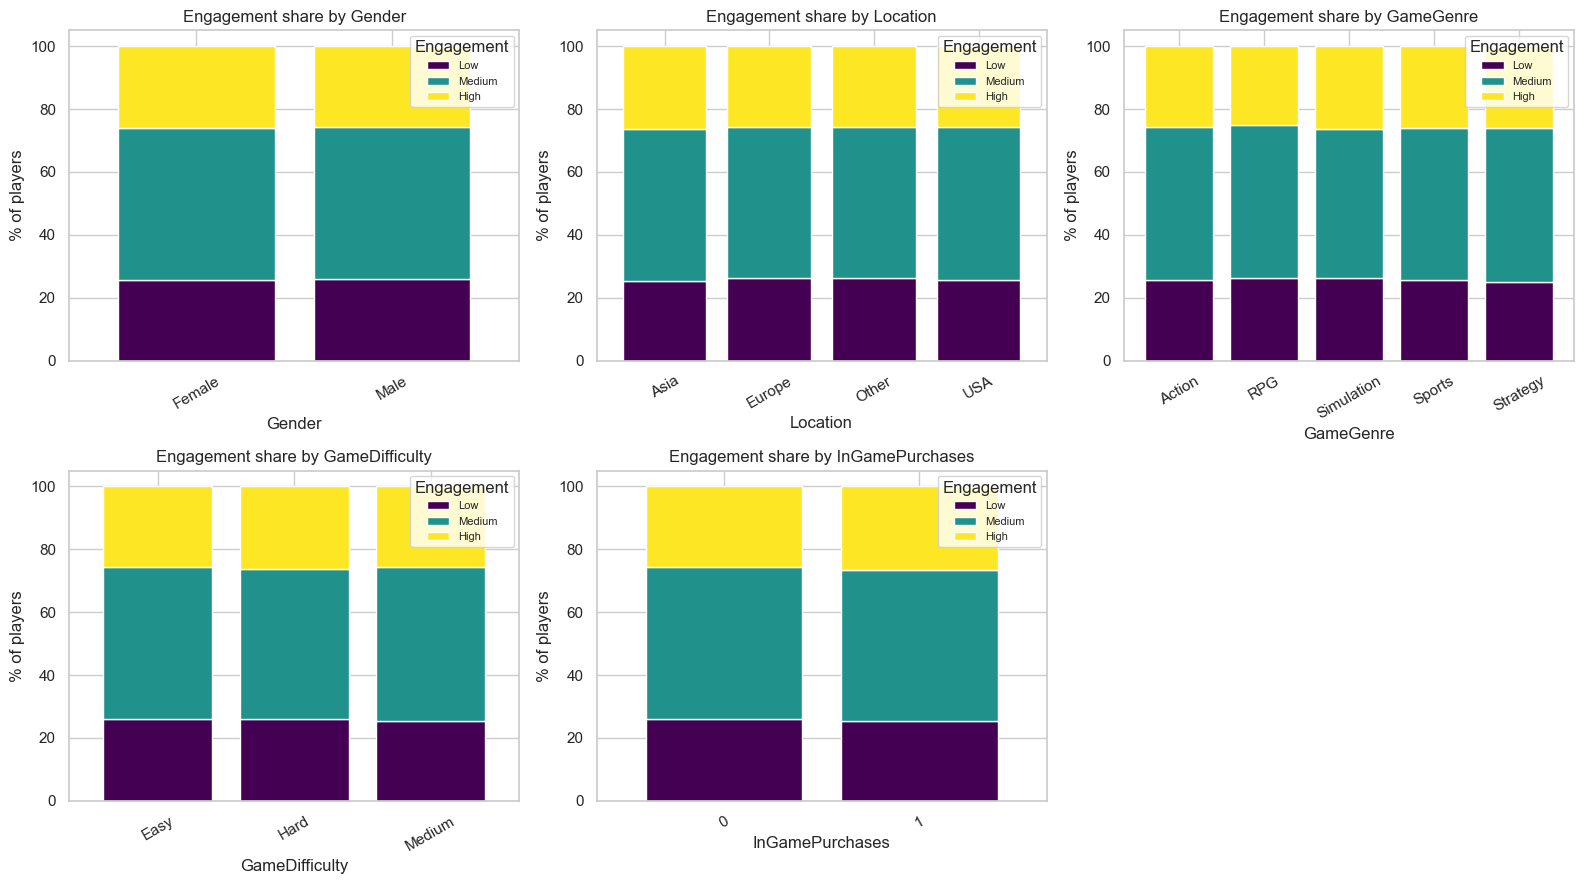

In [5]:
# 3.3 Categorical variables vs engagement (100% stacked bars = share of each engagement level)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), CATEGORICAL_COLS):
    share = pd.crosstab(data[col], data["EngagementLevel"], normalize="index")[ORDER] * 100
    share.plot(kind="bar", stacked=True, colormap="viridis", ax=ax, width=0.8)
    ax.set_title(f"Engagement share by {col}")
    ax.set_ylabel("% of players")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Engagement", fontsize=8)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

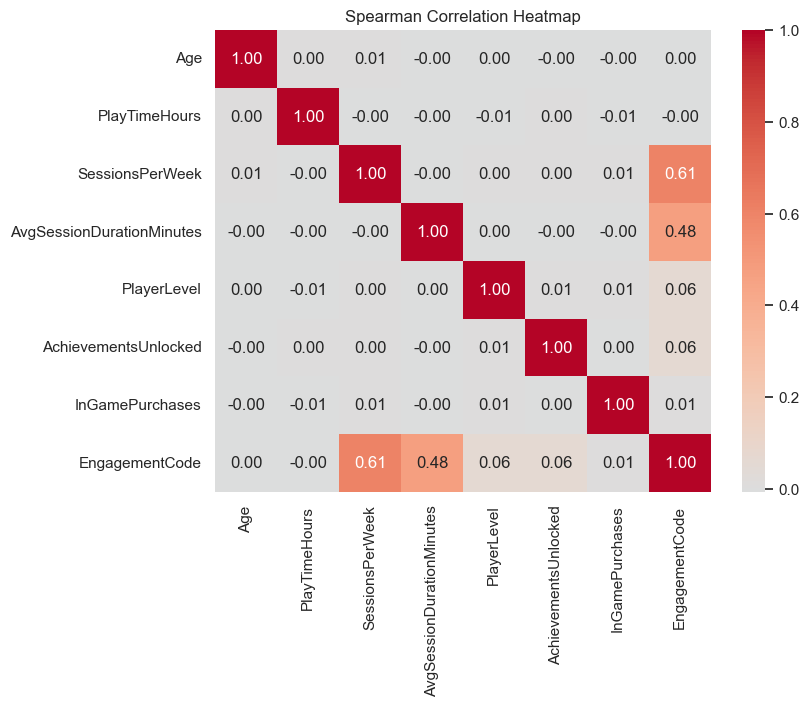

In [6]:
# 3.4 Correlation heatmap (numeric variables + engagement as 0/1/2)
corr_df = data[NUMERIC_COLS + ["InGamePurchases"]].copy()
corr_df["EngagementCode"] = data["EngagementLevel"].cat.codes      # Low=0, Medium=1, High=2

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman Correlation Heatmap")
plt.show()

In [11]:
## 4. Statistical Testing (are the patterns real, and how big are they?)

##Categorical variables → Chi-square test of independence**, effect size = **Cramér's V**.
##Numeric variables → Kruskal–Wallis test** (does not assume normal data, and the box plots show the variables are not normal), effect size = **epsilon-squared (ε²)**.


In [12]:
# 4.1 Chi-square + Cramer's V for categorical variables
def cramers_v(table):
    chi2, p, dof, _ = stats.chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return chi2, p, v

def label_v(v):
    return "negligible" if v < 0.10 else "small" if v < 0.30 else "medium" if v < 0.50 else "large"

rows = []
for col in CATEGORICAL_COLS:
    table = pd.crosstab(data[col], data["EngagementLevel"])
    chi2, p, v = cramers_v(table)
    rows.append([col, round(chi2, 2), p, round(v, 3), label_v(v)])

chi_results = pd.DataFrame(rows, columns=["Variable", "Chi2", "p_value", "Cramers_V", "Effect_size"])
chi_results.sort_values("Cramers_V", ascending=False)

,Variable,Chi2,p_value,Cramers_V,Effect_size
2,GameGenre,8.61,0.376146,0.010,negligible
4,InGamePurchases,2.98,0.225215,0.009,negligible
1,Location,3.56,0.736362,0.007,negligible
3,GameDifficulty,4.17,0.383061,0.007,negligible
0,Gender,1.18,0.554098,0.005,negligible


In [13]:
# 4.2 Kruskal-Wallis + epsilon-squared for numeric variables
def label_eps(e):
    return "negligible" if e < 0.01 else "small" if e < 0.08 else "moderate" if e < 0.26 else "large"

rows = []
n_total = len(data)
k_groups = len(ORDER)
for col in NUMERIC_COLS:
    groups = [data.loc[data["EngagementLevel"] == g, col] for g in ORDER]
    H, p = stats.kruskal(*groups)
    eps2 = max((H - k_groups + 1) / (n_total - k_groups), 0)
    rows.append([col, round(H, 2), p, round(eps2, 4), label_eps(eps2)])

kw_results = pd.DataFrame(rows, columns=["Variable", "H_statistic", "p_value", "Epsilon_squared", "Effect_size"])
kw_results.sort_values("Epsilon_squared", ascending=False)

,Variable,H_statistic,p_value,Epsilon_squared,Effect_size
2,SessionsPerWeek,14742.09,0.000000e+00,0.3682,large
3,AvgSessionDurationMinutes,9467.65,0.000000e+00,0.2365,moderate
5,AchievementsUnlocked,232.98,2.561843e-51,0.0058,negligible
4,PlayerLevel,215.02,2.042082e-47,0.0053,negligible
0,Age,3.01,2.220328e-01,0.0000,negligible
1,PlayTimeHours,3.66,1.603920e-01,0.0000,negligible


In [15]:
##5. Improved Machine Learning Workflow
##Steps: drop PlayerID → stratified 80/20 split → preprocessing inside a Pipeline (fit on training data only) → 3-fold cross-validation with a small hyperparameter search scored on macro F1 → compare against a baseline → evaluate the chosen model once on the held-out test set.

##Why macro F1? It gives each engagement class equal weight, so a model cannot look good just by predicting the biggest class (Medium).

In [16]:
# 5.1 Features, target and stratified split
feature_cols = [c for c in data.columns if c not in ["PlayerID", "EngagementLevel"]]
X_all = data[feature_cols]
y_all = data["EngagementLevel"].astype(str)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)

num_features = X_all.select_dtypes(include="number").columns.tolist()
cat_features = X_all.select_dtypes(exclude="number").columns.tolist()

print("Train:", X_tr.shape, " Test:", X_te.shape)
print("\nClass share (train vs test):")
print(pd.concat([y_tr.value_counts(normalize=True).rename("train"),
                 y_te.value_counts(normalize=True).rename("test")], axis=1).round(3))

Train: (32027, 11)  Test: (8007, 11)

Class share (train vs test):
                 train   test
EngagementLevel              
Medium           0.484  0.484
High             0.258  0.258
Low              0.258  0.258


In [18]:
# 5.2 Pipelines + candidate models
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])

def make_pipeline(model, use_pca=False):
    steps = [("prep", make_preprocessor())]
    if use_pca:
        steps.append(("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# name: (model, search grid, use_pca, rows used for tuning (None = all training rows))
candidates = {
    "Baseline (most frequent)": (DummyClassifier(strategy="most_frequent"), {}, False, None),
    "Logistic Regression": (LogisticRegression(max_iter=1000),
                            {"model__C": [0.1, 1, 10]}, False, None),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {"model__max_depth": [5, 10, 15], "model__min_samples_leaf": [5, 20]}, False, None),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
                      {"model__max_depth": [10, 15, None], "model__min_samples_leaf": [2, 5]}, False, None),
    "KNN (no PCA)": (KNeighborsClassifier(),
                     {"model__n_neighbors": [5, 9, 15, 25]}, False, None),
    "KNN (with PCA)": (KNeighborsClassifier(),
                       {"model__n_neighbors": [5, 9, 15, 25]}, True, None),
    "SVM (RBF)": (SVC(random_state=RANDOM_STATE),
                  {"model__C": [1, 10]}, False, 8000),   # SVM is slow -> tune on 8,000 rows, refit on all
}
print("Models to compare:", list(candidates))

Models to compare: ['Baseline (most frequent)', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN (no PCA)', 'KNN (with PCA)', 'SVM (RBF)']


In [19]:
# 5.3 Train, cross-validate and evaluate every model (takes a few minutes)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

final_models = {}
rows = []

for name, (model, grid, use_pca, tune_rows) in candidates.items():
    pipe = make_pipeline(model, use_pca)

    if not grid:                                   # baseline: nothing to tune
        cv_f1 = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro").mean()
        fitted = pipe.fit(X_tr, y_tr)
        best_params = {}
    else:
        if tune_rows and len(X_tr) > tune_rows:    # stratified subsample for slow models
            X_tune, _, y_tune, _ = train_test_split(X_tr, y_tr, train_size=tune_rows,
                                                    stratify=y_tr, random_state=RANDOM_STATE)
        else:
            X_tune, y_tune = X_tr, y_tr
        search = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=-1)
        search.fit(X_tune, y_tune)
        cv_f1 = search.best_score_
        best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
        if X_tune is X_tr:
            fitted = search.best_estimator_
        else:
            fitted = clone(pipe).set_params(**search.best_params_).fit(X_tr, y_tr)

    final_models[name] = fitted
    pred = fitted.predict(X_te)
    rows.append({
        "Model": name,
        "CV_Macro_F1": round(cv_f1, 4),
        "Test_Accuracy": round(accuracy_score(y_te, pred), 4),
        "Test_Precision_macro": round(precision_score(y_te, pred, average="macro", zero_division=0), 4),
        "Test_Recall_macro": round(recall_score(y_te, pred, average="macro", zero_division=0), 4),
        "Test_Macro_F1": round(f1_score(y_te, pred, average="macro", zero_division=0), 4),
        "Best_Params": best_params,
    })
    print(f"done: {name}")

model_results = pd.DataFrame(rows).sort_values("CV_Macro_F1", ascending=False).reset_index(drop=True)
model_results

done: Baseline (most frequent)
done: Logistic Regression
done: Decision Tree
done: Random Forest
done: KNN (no PCA)
done: KNN (with PCA)
done: SVM (RBF)


,Model,CV_Macro_F1,Test_Accuracy,Test_Precision_macro,Test_Recall_macro,Test_Macro_F1,Best_Params
0,Decision Tree,0.8947,0.9016,0.9006,0.8924,0.8963,"{'max_depth': 10, 'min_samples_leaf': 5}"
1,Random Forest,0.8891,0.8926,0.8993,0.8774,0.8870,"{'max_depth': None, 'min_samples_leaf': 2}"
2,SVM (RBF),0.8630,0.8982,0.9023,0.8854,0.8930,{'C': 1}
3,Logistic Regression,0.8176,0.8183,0.8256,0.8004,0.8110,{'C': 10}
4,KNN (with PCA),0.7901,0.8067,0.8368,0.7716,0.7930,{'n_neighbors': 25}
5,KNN (no PCA),0.7828,0.8037,0.8359,0.7676,0.7897,{'n_neighbors': 25}
6,Baseline (most frequent),0.2174,0.4840,0.1613,0.3333,0.2174,{}


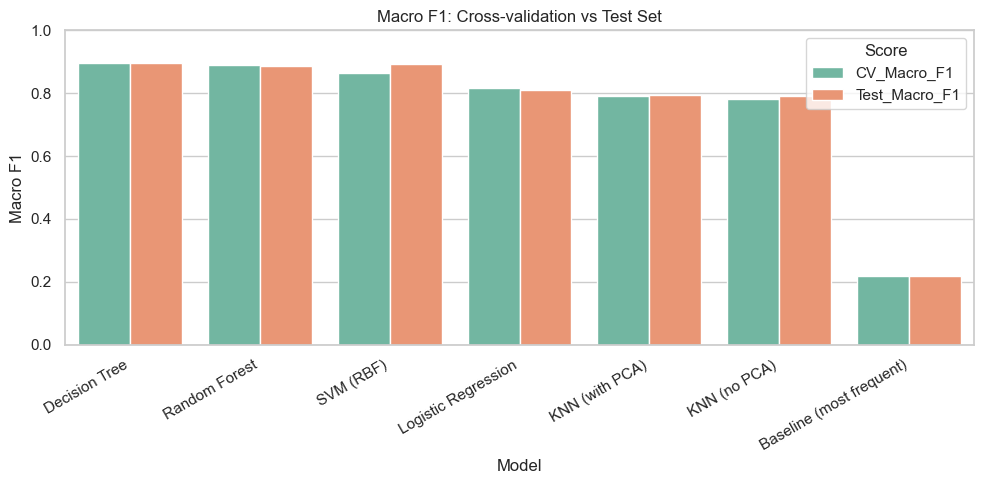

In [21]:
# 5.4 Compare models visually (cross-validation vs held-out test)
plot_df = model_results.melt(id_vars="Model", value_vars=["CV_Macro_F1", "Test_Macro_F1"],
                             var_name="Score", value_name="Macro F1")
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_df, x="Model", y="Macro F1", hue="Score", palette="Set2")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.title("Macro F1: Cross-validation vs Test Set")
plt.tight_layout()
plt.show()

Selected model: Decision Tree

              precision    recall  f1-score   support

         Low       0.90      0.87      0.88      2065
      Medium       0.90      0.93      0.92      3875
        High       0.90      0.88      0.89      2067

    accuracy                           0.90      8007
   macro avg       0.90      0.89      0.90      8007
weighted avg       0.90      0.90      0.90      8007



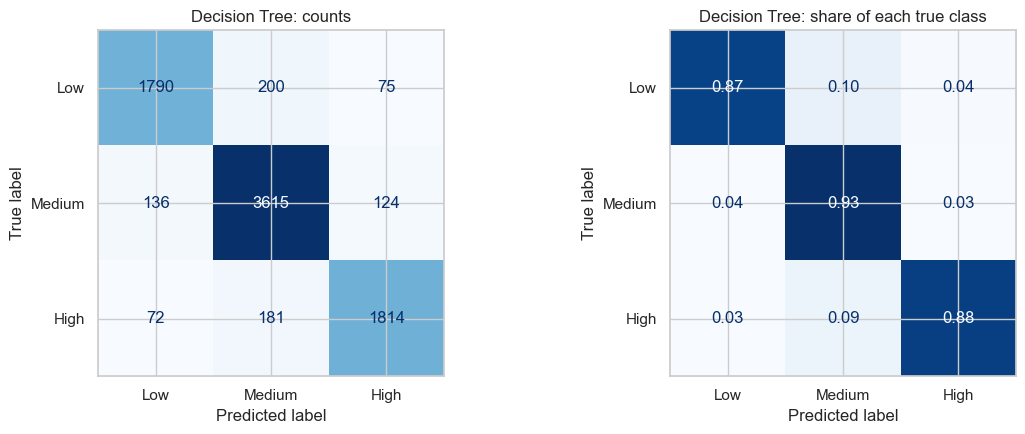

9.7% of truly 'Low' players were predicted as 'Medium'
8.8% of truly 'High' players were predicted as 'Medium'
3.6% of truly 'Low' players were predicted as 'High'


In [22]:
# 5.5 Final model = best CROSS-VALIDATION macro F1 (chosen without looking at the test set)
best_name = model_results.loc[0, "Model"]
best_model = final_models[best_name]
best_pred = best_model.predict(X_te)
print("Selected model:", best_name)
print()
print(classification_report(y_te, best_pred, labels=ORDER, zero_division=0))

cm_best = confusion_matrix(y_te, best_pred, labels=ORDER)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm_best, display_labels=ORDER).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"{best_name}: counts")
ConfusionMatrixDisplay(confusion_matrix(y_te, best_pred, labels=ORDER, normalize="true"),
                       display_labels=ORDER).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title(f"{best_name}: share of each true class")
plt.tight_layout()
plt.show()

# Which classes does the model confuse most?
cm_norm = confusion_matrix(y_te, best_pred, labels=ORDER, normalize="true")
confusions = [(ORDER[i], ORDER[j], cm_norm[i, j]) for i in range(3) for j in range(3) if i != j]
for true_c, pred_c, share in sorted(confusions, key=lambda t: -t[2])[:3]:
    print(f"{share:.1%} of truly '{true_c}' players were predicted as '{pred_c}'")

In [ ]:
##Reading the model comparison**

#Compare every model with the **baseline**: a model is only useful if it clearly beats "always predict the most common class".
#Compare **CV vs test** scores: if they are close, the result is stable; a big gap would suggest over-fitting.
#Compare **KNN with vs without PCA** instead of assuming PCA helps.
# The model is chosen by cross-validation, so the test set stays an honest final check.
#Numbers here can differ from the original section because the split is now stratified, `PlayerID` is removed and settings are tuned.

In [ ]:
#6. Explainability — what drives the predictions?
#Two views are used so the ranking is not based on one method only:

#Random Forest impurity importance (how much each feature helps the trees split; one-hot columns are added back up to their original feature).
#Permutation importance on the test set (how much macro F1 drops when a feature is shuffled).


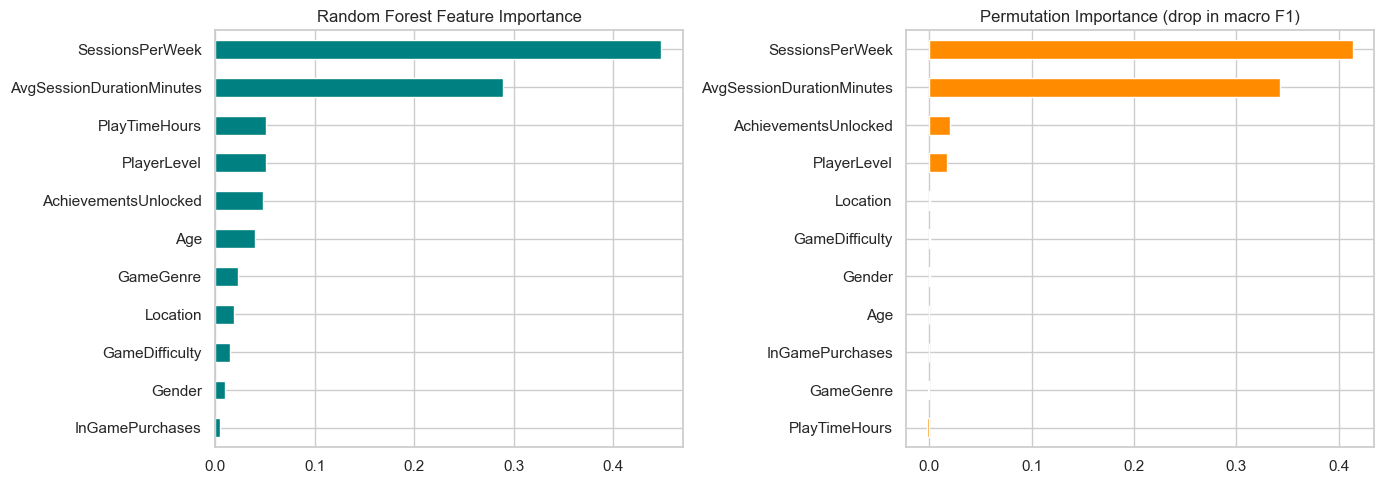

,RF_Importance,RF_Rank,Permutation_Importance,Permutation_Rank
SessionsPerWeek,0.4476,1,0.4136,1
AvgSessionDurationMinutes,0.2893,2,0.3429,2
PlayTimeHours,0.0514,3,-0.0017,11
PlayerLevel,0.0513,4,0.0175,4
AchievementsUnlocked,0.0480,5,0.0201,3
Age,0.0401,6,-0.0004,8
GameGenre,0.0233,7,-0.0010,10
Location,0.0190,8,0.0008,5
GameDifficulty,0.0150,9,0.0007,6
Gender,0.0096,10,0.0004,7


In [26]:
# 6.1 Random Forest importance, grouped back to original features
rf_pipe = final_models["Random Forest"]
prep = rf_pipe.named_steps["prep"]
rf_model = rf_pipe.named_steps["model"]
encoded_names = prep.get_feature_names_out()

def original_feature(encoded_name):
    if encoded_name.startswith("num__"):
        return encoded_name[len("num__"):]
    rest = encoded_name[len("cat__"):]
    for col in cat_features:
        if rest.startswith(col + "_"):
            return col
    return rest

imp_rf = (pd.Series(rf_model.feature_importances_, index=[original_feature(n) for n in encoded_names])
            .groupby(level=0).sum().sort_values(ascending=False))

# 6.2 Permutation importance (on raw columns through the whole pipeline)
perm = permutation_importance(rf_pipe, X_te, y_te, scoring="f1_macro",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X_te.columns).sort_values(ascending=False)

importance_table = pd.DataFrame({
    "RF_Importance": imp_rf.round(4),
    "RF_Rank": imp_rf.rank(ascending=False).astype(int),
    "Permutation_Importance": imp_perm.reindex(imp_rf.index).round(4),
    "Permutation_Rank": imp_perm.rank(ascending=False).reindex(imp_rf.index).astype(int),
}).sort_values("RF_Rank")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
imp_rf.sort_values().plot(kind="barh", ax=axes[0], color="teal")
axes[0].set_title("Random Forest Feature Importance")
imp_perm.sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Permutation Importance (drop in macro F1)")
plt.tight_layout()
plt.show()

importance_table

In [27]:
# 6.3 Does SessionsPerWeek still matter after accounting for playtime and session length?
# Partial correlation = correlation between the leftovers (residuals) after removing the other variables' effect
def partial_corr(df_, x, y, controls):
    rx = df_[x] - LinearRegression().fit(df_[controls], df_[x]).predict(df_[controls])
    ry = df_[y] - LinearRegression().fit(df_[controls], df_[y]).predict(df_[controls])
    return stats.spearmanr(rx, ry)[0]

tmp = data[["SessionsPerWeek", "PlayTimeHours", "AvgSessionDurationMinutes"]].copy()
tmp["EngagementCode"] = data["EngagementLevel"].cat.codes

raw_r = stats.spearmanr(tmp["SessionsPerWeek"], tmp["EngagementCode"])[0]
adj_r = partial_corr(tmp, "SessionsPerWeek", "EngagementCode", ["PlayTimeHours", "AvgSessionDurationMinutes"])
print(f"SessionsPerWeek vs engagement  - raw correlation:        {raw_r:.3f}")
print(f"SessionsPerWeek vs engagement  - after controlling for")
print(f"PlayTimeHours and AvgSessionDurationMinutes:              {adj_r:.3f}")

SessionsPerWeek vs engagement  - raw correlation:        0.607
SessionsPerWeek vs engagement  - after controlling for
PlayTimeHours and AvgSessionDurationMinutes:              0.709


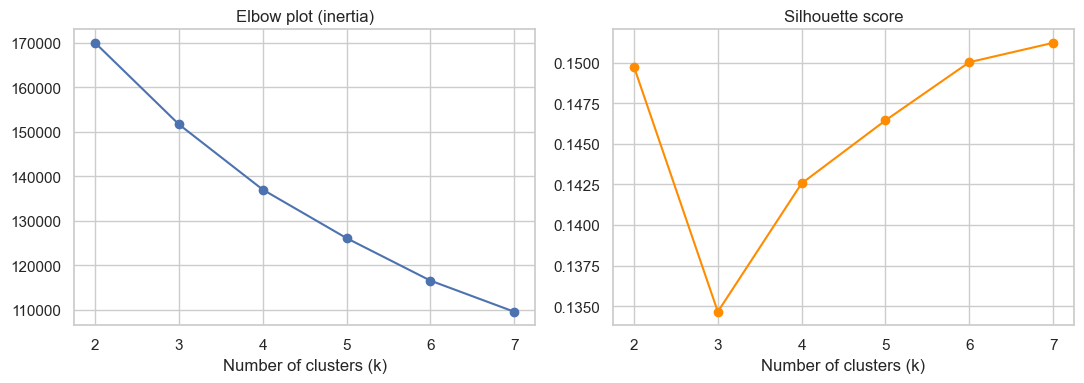

   k     Inertia  Silhouette
0  2  170021.073       0.150
1  3  151698.052       0.135
2  4  137040.968       0.143
3  5  126141.519       0.146
4  6  116598.504       0.150
5  7  109603.260       0.151

Best k by silhouette: 7
Best silhouette: 0.151
Note: silhouette is low, so clusters overlap a lot. Treat segments as rough groupings, not sharp types.


In [28]:
# 7.1 Choose the number of clusters
SEG_FEATURES = ["PlayTimeHours", "SessionsPerWeek", "AvgSessionDurationMinutes",
                "AchievementsUnlocked", "PlayerLevel"]

seg_scaler = StandardScaler()
X_seg = seg_scaler.fit_transform(data[SEG_FEATURES])

sil_rows = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_seg)
    sil = silhouette_score(X_seg, labels, sample_size=10000, random_state=RANDOM_STATE)  # sampled for speed
    sil_rows.append([k, km.inertia_, sil])

sil_df = pd.DataFrame(sil_rows, columns=["k", "Inertia", "Silhouette"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sil_df["k"], sil_df["Inertia"], marker="o")
axes[0].set_title("Elbow plot (inertia)")
axes[0].set_xlabel("Number of clusters (k)")
axes[1].plot(sil_df["k"], sil_df["Silhouette"], marker="o", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

best_k = int(sil_df.loc[sil_df["Silhouette"].idxmax(), "k"])
print(sil_df.round(3))
print("\nBest k by silhouette:", best_k)
print("Best silhouette:", round(sil_df['Silhouette'].max(), 3))
if sil_df["Silhouette"].max() < 0.25:
    print("Note: silhouette is low, so clusters overlap a lot. Treat segments as rough groupings, not sharp types.")

In [33]:

top3 = list(imp_perm.index[:3])

print("MODEL")
print(f"- Best model by cross-validation: {best_name}")
print(
    f"- Test macro F1: {model_results.loc[0, 'Test_Macro_F1']}   |   "
    f"Test accuracy: {model_results.loc[0, 'Test_Accuracy']}"
)

base_f1 = model_results.loc[
    model_results['Model'] == 'Baseline (most frequent)',
    'Test_Macro_F1'
].iloc[0]

print(f"- Baseline test macro F1: {base_f1}")

print("\nTOP PREDICTORS (permutation importance)")
print("- " + ", ".join(top3))

print("\nSTATISTICAL TESTS")

print("- Numeric variables with the largest effect size:")
print(
    kw_results.sort_values("Epsilon_squared", ascending=False)
    .head(3)[["Variable", "Epsilon_squared", "Effect_size"]]
    .to_string(index=False)
)

print("- Categorical variables with the largest effect size:")
print(
    chi_results.sort_values("Cramers_V", ascending=False)
    .head(3)[["Variable", "Cramers_V", "Effect_size"]]
    .to_string(index=False)
)

print("\nSEGMENTS")

print(f"- Best silhouette score: {sil_df['Silhouette'].max():.3f}")

if 'profile' in globals():
    print(f"- Number of segments: {len(profile)}")
    print("\nSegment shares:")
    print(profile['Share_%'].to_string())
else:
    print("- Segment profile is not available.")
    print("- Run the earlier cell that creates the 'profile' DataFrame.")


MODEL
- Best model by cross-validation: Decision Tree
- Test macro F1: 0.8963   |   Test accuracy: 0.9016
- Baseline test macro F1: 0.2174

TOP PREDICTORS (permutation importance)
- SessionsPerWeek, AvgSessionDurationMinutes, AchievementsUnlocked

STATISTICAL TESTS
- Numeric variables with the largest effect size:
                 Variable  Epsilon_squared Effect_size
          SessionsPerWeek           0.3682       large
AvgSessionDurationMinutes           0.2365    moderate
     AchievementsUnlocked           0.0058  negligible
- Categorical variables with the largest effect size:
       Variable  Cramers_V Effect_size
      GameGenre      0.010  negligible
InGamePurchases      0.009  negligible
       Location      0.007  negligible

SEGMENTS
- Best silhouette score: 0.151
- Segment profile is not available.
- Run the earlier cell that creates the 'profile' DataFrame.
